# PatchVision: Advanced Preprocessing for a Small-Data Regime

| Section | Question it answers |
|---|---|
| A | How much data do we really have, and how noisy will our metrics be? |
| B | Which resize strategy hurts the bird least? |
| C | What does each augmentation do to an image? |
| D | How aggressive can random crops be before the bird disappears? |
| E | Augmentation pipelines for experiment E4 |
| F | Mixup / CutMix for a very small dataset |
| G | Data quality and leakage audit |
| H | Save the config for reproducibility |

In [3]:
import json, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2
ROOT = Path("data"); CUB = ROOT / "CUB_200_2011"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- rebuild the full metadata table (same logic as the first notebook) ----
images  = pd.read_csv(CUB/"images.txt", sep=" ", names=["image_id", "path"])
labels  = pd.read_csv(CUB/"image_class_labels.txt", sep=" ", names=["image_id", "class_id"])
split_f = pd.read_csv(CUB/"train_test_split.txt", sep=" ", names=["image_id", "is_train"])
classes = pd.read_csv(CUB/"classes.txt", sep=" ", names=["class_id", "class_name"])
bbox    = pd.read_csv(CUB/"bounding_boxes.txt", sep=" ", names=["image_id", "x", "y", "w", "h"])
meta = (images.merge(labels, on="image_id")
              .merge(split_f, on="image_id")
              .merge(classes, on="class_id")
              .merge(bbox, on="image_id"))
meta["label"] = meta["class_id"] - 1
meta["class_name"] = meta["class_name"].str.split(".", n=1).str[1].str.replace("_", " ")
meta["filepath"] = meta["path"].apply(lambda p: str(CUB/"images"/p))

# ---- get the train/val/test split: load saved CSVs, or rebuild the identical split ----
split_files = [ROOT/f"{n}.csv" for n in ["train", "val", "test"]]
if all(f.exists() for f in split_files):
    ids = {n: pd.read_csv(ROOT/f"{n}.csv")["image_id"] for n in ["train", "val", "test"]}
else:
    print("Saved split not found: rebuilding it with the same seed and stratification.")
    train_full = meta[meta.is_train == 1].reset_index(drop=True)
    test_part  = meta[meta.is_train == 0].reset_index(drop=True)
    tr, va = train_test_split(train_full, test_size=0.10, random_state=SEED,
                              stratify=train_full["label"])
    cols = ["image_id", "filepath", "label", "class_name"]
    tr.reset_index(drop=True)[cols].to_csv(ROOT/"train.csv", index=False)
    va.reset_index(drop=True)[cols].to_csv(ROOT/"val.csv", index=False)
    test_part[cols].to_csv(ROOT/"test.csv", index=False)
    ids = {"train": tr["image_id"], "val": va["image_id"], "test": test_part["image_id"]}

parts = []
for name in ["train", "val", "test"]:
    part = meta[meta.image_id.isin(ids[name])].copy(); part["split"] = name
    parts.append(part)
df = pd.concat(parts, ignore_index=True)

# ---- image header info (fast, no pixel decoding) ----
def hdr(fp):
    with Image.open(fp) as im:
        return im.size[0], im.size[1], im.mode
hd = df["filepath"].map(hdr)
df["width"]  = [h[0] for h in hd]
df["height"] = [h[1] for h in hd]
df["mode"]   = [h[2] for h in hd]
df["aspect"] = df.width / df.height
df["bbox_frac"] = (df.w * df.h) / (df.width * df.height)

train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "val"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)
print(len(train_df), len(val_df), len(test_df))   # expect 5394 600 5794

Saved split not found: rebuilding it with the same seed and stratification.
5394 600 5794


In [5]:
# ---- normalization stats: load if saved, otherwise compute on TRAIN only ----
NUM_WORKERS = 0   # avoids the shared-memory (shm) crash; later cells reuse this value

STATS = ROOT/"norm_stats.json"
class _DS(Dataset):
    def __init__(self, frame, tfm, col="filepath"):
        self.fp, self.y, self.tfm = frame[col].tolist(), frame["label"].tolist(), tfm
    def __len__(self): return len(self.fp)
    def __getitem__(self, i):
        return self.tfm(Image.open(self.fp[i]).convert("RGB")), self.y[i]

if STATS.exists():
    st = json.loads(STATS.read_text()); MEAN, STD = st["mean"], st["std"]
else:
    dl = DataLoader(_DS(train_df, T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor()])),
                    batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
    n, s, s2 = 0, torch.zeros(3), torch.zeros(3)
    for x, _ in dl:
        s += x.mean(dim=[2, 3]).sum(0); s2 += (x ** 2).mean(dim=[2, 3]).sum(0); n += x.size(0)
    m = s / n; sd = (s2 / n - m ** 2).sqrt()
    MEAN, STD = m.tolist(), sd.tolist()
    STATS.write_text(json.dumps({"mean": MEAN, "std": STD}))
print("MEAN", [round(v, 4) for v in MEAN], "STD", [round(v, 4) for v in STD])

MEAN [0.486, 0.4992, 0.4314] STD [0.2265, 0.222, 0.2609]


## Normalization Statistics

**What this step does**
- Computes the **mean** and **standard deviation** of the pixel values in the training images, separately for each color channel (R, G, B).
- Images are resized to 224 × 224 with no augmentation, so the numbers describe the clean images.
- Only the **training split** (5,394 images) is used, so nothing from validation or test leaks into preprocessing.
- The result is saved to `data/norm_stats.json`, so it is computed once and loaded on later runs.

**Why we need it**
- Raw pixel values range from 0 to 1. Normalization subtracts the mean and divides by the std (`Normalize(MEAN, STD)`), so inputs are centered near 0 with a spread near 1.
- This makes training more stable, which matters for a Vision Transformer trained from scratch.
- Dataset-specific statistics are used instead of the standard ImageNet values, since the model is not pretrained.

**Output**

| Channel | Mean | Std |
|---|---|---|
| R | 0.486 | 0.2265 |
| G | 0.4992 | 0.222 |
| B | 0.4314 | 0.2609 |

**What the output tells us**
- Split sizes are **5,394 train, 600 val, 5,794 test**, as expected.
- Blue has the lowest mean (0.43) and the highest std (0.26). This fits bird photos, where backgrounds are often green (grass, trees) or brown (rocks, ground), with occasional bright blue sky or water.
- Mean values near 0.5 mean the images are neither very dark nor very bright overall.
- These six numbers are used by `Normalize` in every training and evaluation pipeline, for both the CNN and the ViT.

**Note**
- `NUM_WORKERS = 0` is set here to avoid a shared-memory crash in the notebook environment. It makes loading slower but does not change the results.

## A. How much data do we really have?
Three numbers shape every later decision: training images per class, validation images per class, and the model-size-to-data ratio.

**Why it matters**
- A ViT has no built-in assumption about locality, so it has to learn spatial structure from the data. About 27 images per class gives it very little to learn from.
- A tiny validation set makes accuracy noisy. If two ablation runs differ by less than the noise, you cannot say which is better. This is the reason for the three-seed runs 

In [6]:
tr_pc = train_df.groupby("label").size(); va_pc = val_df.groupby("label").size()
print(f"train images/class: min={tr_pc.min()} max={tr_pc.max()} mean={tr_pc.mean():.1f}")
print(f"val   images/class: min={va_pc.min()} max={va_pc.max()} mean={va_pc.mean():.1f}")

# Approximate ViT size for the proposal config (assumes MLP ratio 4, 6 blocks, d=384, 16x16 patches, 200 classes)
d, L, P, C = 384, 6, 16, 200
params = L * 12 * d * d + (P * P * 3) * d + d * C
print(f"\napprox ViT parameters: {params/1e6:.1f}M  vs  {len(train_df)} training images "
      f"-> about {params/len(train_df):,.0f} parameters per training image")

# Accuracy noise: 95% confidence half-width for a measured accuracy on n images (normal approximation)
def acc_ci(acc, n, z=1.96):
    return z * np.sqrt(acc * (1 - acc) / n)

print("\n95% CI half-width (+/- accuracy points):")
rows = []
for acc in [0.10, 0.20, 0.30, 0.50]:
    rows.append({"true acc": acc,
                 f"val (n={len(val_df)})": round(100 * acc_ci(acc, len(val_df)), 1),
                 f"test (n={len(test_df)})": round(100 * acc_ci(acc, len(test_df)), 1)})
print(pd.DataFrame(rows).to_string(index=False))

train images/class: min=26 max=27 mean=27.0
val   images/class: min=3 max=3 mean=3.0

approx ViT parameters: 11.0M  vs  5394 training images -> about 2,037 parameters per training image

95% CI half-width (+/- accuracy points):
 true acc  val (n=600)  test (n=5794)
      0.1          2.4            0.8
      0.2          3.2            1.0
      0.3          3.7            1.2
      0.5          4.0            1.3


## A. Data Budget and Metric Noise

**What this step does**
- Counts how many images each class has in the training and validation splits.
- Compares the size of the ViT (number of parameters) with the number of training images.
- Estimates how much accuracy numbers can wobble just by chance, for the validation set and the test set.

**Images per class**

| Split | Per class | Total |
|---|---|---|
| Train | 26 to 27 (mean 27.0) | 5,394 |
| Validation | exactly 3 | 600 |

- Training classes are almost perfectly balanced. Validation has exactly 3 images for every species.

**Model size vs. data size**
- The proposed ViT (6 blocks, 384-dim embeddings, 16×16 patches) has about **11.0M parameters**. This is an approximation that assumes the usual 4× feed-forward width.
- With 5,394 training images, that is about **2,037 parameters per training image**.
- The model is far larger than the data, so **overfitting is the main risk**.

**How noisy is accuracy? (95% confidence interval, ± accuracy points)**

| True accuracy | Validation (n = 600) | Test (n = 5,794) |
|---|---|---|
| 10% | ± 2.4 | ± 0.8 |
| 20% | ± 3.2 | ± 1.0 |
| 30% | ± 3.7 | ± 1.2 |
| 50% | ± 4.0 | ± 1.3 |

- How to read it: if a model's true accuracy is 30%, its measured validation accuracy can land anywhere from about 26% to 34% by chance alone.
- The test set has about 10× more images, so its interval is much tighter.

**What this means for the project**
- Heavy regularization is justified: augmentation, weight decay, dropout and label smoothing.
- On validation, a gap of 2 to 4 points between two runs is within noise, so it cann

**Implication for the report**
- Parameters outnumber training images by roughly three orders of magnitude, so overfitting is the main risk. This supports heavy augmentation, weight decay, dropout and label smoothing.here the interval is about ± 1 point.

## B. Resize strategy: which one hurts the bird least?
Three options for turning a 500x375 photo into 224x224:

| Strategy | What happens | Risk |
|---|---|---|
| **Squash** | Resize straight to 224x224 | Distorts shape (stretches non-square photos) |
| **Resize 256 + CenterCrop 224** | Keep aspect ratio, cut the borders | May cut off part of the bird |
| **Letterbox** | Keep aspect ratio, pad to a square | Bird gets smaller, wasted pixels |

Instead of guessing, the next cell measures the cost of each using the bounding boxes.

In [7]:
def centercrop_bbox_retained(r, resize=256, crop=IMG_SIZE):
    """Fraction of the bird's bounding-box area that survives Resize(resize) + CenterCrop(crop)."""
    s = resize / min(r.width, r.height)
    W, H = r.width * s, r.height * s
    left, top = (W - crop) / 2, (H - crop) / 2
    x0, y0, x1, y1 = r.x * s, r.y * s, (r.x + r.w) * s, (r.y + r.h) * s
    ix = max(0.0, min(x1, left + crop) - max(x0, left))
    iy = max(0.0, min(y1, top + crop) - max(y0, top))
    return (ix * iy) / ((x1 - x0) * (y1 - y0))

df["kept_centercrop"] = df.apply(centercrop_bbox_retained, axis=1)
df["squash_stretch"]  = np.maximum(df.aspect, 1 / df.aspect)           # 1.0 = no distortion
df["bbox_frac_letterbox"] = df.bbox_frac * (df.width * df.height) / (np.maximum(df.width, df.height) ** 2)

print("SQUASH")
print(f"  median stretch factor: {df.squash_stretch.median():.2f}x | images stretched > 1.5x: {(df.squash_stretch > 1.5).mean():.1%}")
print("CENTER CROP")
print(f"  mean bird area kept: {df.kept_centercrop.mean():.1%} | images losing > 10% of the bird: {(df.kept_centercrop < 0.9).mean():.1%}"
      f" | losing > 30%: {(df.kept_centercrop < 0.7).mean():.1%}")
print("LETTERBOX")
print(f"  bird fraction of frame: median {df.bbox_frac.median():.1%} (squash/crop) -> {df.bbox_frac_letterbox.median():.1%} (letterbox)")

SQUASH
  median stretch factor: 1.38x | images stretched > 1.5x: 28.3%
CENTER CROP
  mean bird area kept: 89.1% | images losing > 10% of the bird: 44.8% | losing > 30%: 7.6%
LETTERBOX
  bird fraction of frame: median 31.7% (squash/crop) -> 23.3% (letterbox)


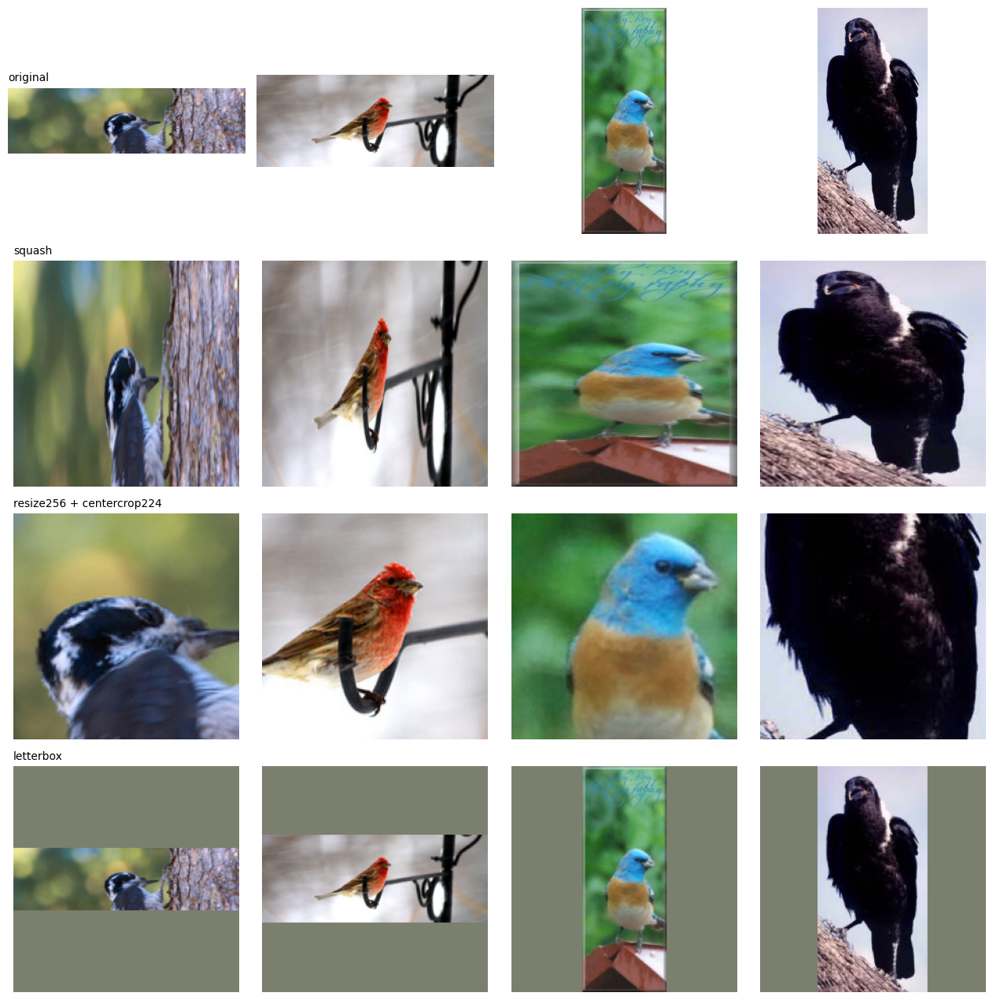

In [8]:
# Visual comparison on the most extreme aspect ratios
def squash(im):    return im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
def centercrop(im): return T.CenterCrop(IMG_SIZE)(T.Resize(256)(im))
def letterbox(im):
    w, h = im.size; s = IMG_SIZE / max(w, h)
    small = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BILINEAR)
    canvas = Image.new("RGB", (IMG_SIZE, IMG_SIZE), tuple(int(m * 255) for m in MEAN))
    canvas.paste(small, ((IMG_SIZE - small.width) // 2, (IMG_SIZE - small.height) // 2))
    return canvas

ex = pd.concat([df.nlargest(2, "aspect"), df.nsmallest(2, "aspect")])
fns = [("original", lambda im: im.resize((IMG_SIZE, int(IMG_SIZE * im.height / im.width)))),
       ("squash", squash), ("resize256 + centercrop224", centercrop), ("letterbox", letterbox)]
fig, axes = plt.subplots(len(fns), len(ex), figsize=(3.2 * len(ex), 3.2 * len(fns)))
for c, (_, r) in enumerate(ex.iterrows()):
    im = Image.open(r.filepath).convert("RGB")
    for rr, (name, fn) in enumerate(fns):
        axes[rr, c].imshow(fn(im)); axes[rr, c].axis("off")
        if c == 0: axes[rr, c].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## B. Resize Strategy Comparison

**What this step does**
- Tests three ways of turning a photo into a 224 × 224 square, and measures what each one costs the bird.
- Uses the bounding boxes, so the cost is measured on real birds instead of guessed.

**The three strategies**

| Strategy | What happens | Main risk |
|---|---|---|
| Squash | Resize straight to 224 × 224 | Stretches the bird's shape |
| Resize 256 + CenterCrop 224 | Keep the aspect ratio, cut the borders | Cuts off part of the bird |
| Letterbox | Keep the aspect ratio, pad to a square | Bird gets smaller |

**Results**

| Strategy | Measurement | Value |
|---|---|---|
| Squash | Median stretch factor | 1.38× |
| Squash | Images stretched more than 1.5× | 28.3% |
| Center crop | Mean bird area kept | 89.1% |
| Center crop | Images losing more than 10% of the bird | 44.8% |
| Center crop | Images losing more than 30% of the bird | 7.6% |
| Letterbox | Bird share of the frame (median) | 31.7% → 23.3% |

**How to read it**
- **Squash:** the whole bird is always kept, but shapes are distorted. The typical image is stretched 1.38×, and about 1 in 4 is stretched more than 1.5×.
- **Center crop:** the bird is not distorted, but nearly half of the images lose more than 10% of the bird, and 7.6% lose more than 30%. A bird cut at the edge can remove the very cue (head, tail, wing) that identifies the species.
- **Letterbox:** no distortion and no cropping, but the bird shrinks by about a quarter (31.7% → 23.3% of the frame). The empty padding also takes up patches that carry no information, which hurts a ViT that already struggles with small birds.

**Decision**
- Use **squash (direct resize to 224 × 224)** for validation and test, as stated in the proposal.
- Reason: it never removes part of the bird, and the stretch is moderate for most images. Cropping and shrinking both lose information the model needs.
- Apply the same resize to the CNN and the ViT, so the comparison stays fair.

**Limitation to mention in the report**
- Squashing distorts the aspect ratio of non-square photos. About 28% are stretched more than 1.5×.
- Center crop can be run as a s

**Implication for the report**
- Read the printed numbers: if center crop cuts a meaningful share of birds, squash is the safer default for eval. If squash stretches few images beyond 1.5x, its distortion is a minor cost.mall extra experiment if time allows.

## C. What does each augmentation actually do?
Augmentations that destroy the discriminating cue (for birds: color patches, beak shape, small markings) hurt more than they help.

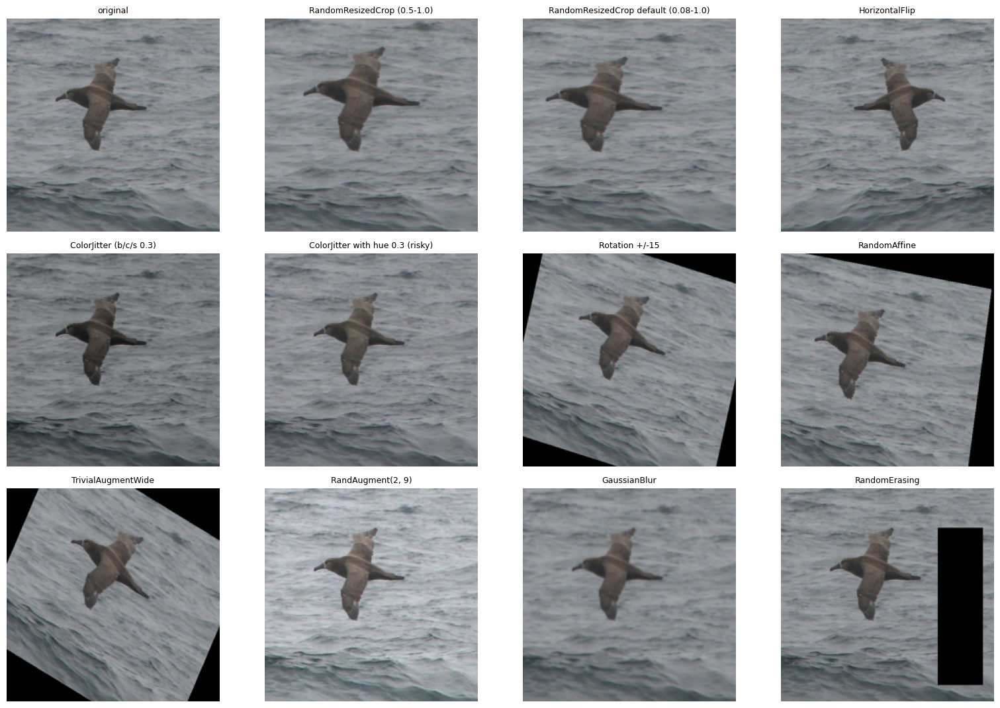

In [9]:
def _erase(im):
    t = T.RandomErasing(p=1.0, scale=(0.05, 0.2), value=0)(T.ToTensor()(im))
    return T.ToPILImage()(t)

augs = [
    ("original", lambda im: im),
    ("RandomResizedCrop (0.5-1.0)", T.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0))),
    ("RandomResizedCrop default (0.08-1.0)", T.RandomResizedCrop(IMG_SIZE)),
    ("HorizontalFlip", T.RandomHorizontalFlip(p=1.0)),
    ("ColorJitter (b/c/s 0.3)", T.ColorJitter(0.3, 0.3, 0.3, 0.0)),
    ("ColorJitter with hue 0.3 (risky)", T.ColorJitter(0.0, 0.0, 0.0, 0.3)),
    ("Rotation +/-15", T.RandomRotation(15)),
    ("RandomAffine", T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.85, 1.15))),
    ("TrivialAugmentWide", T.TrivialAugmentWide()),
    ("RandAugment(2, 9)", T.RandAugment(num_ops=2, magnitude=9)),
    ("GaussianBlur", T.GaussianBlur(7, sigma=(0.5, 2.0))),
    ("RandomErasing", _erase),
]
im = Image.open(train_df.filepath[3]).convert("RGB")
cols = 4; rows = int(np.ceil(len(augs) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.6 * rows))
for ax, (name, fn) in zip(axes.ravel(), augs):
    out = fn(im); ax.imshow(out.resize((IMG_SIZE, IMG_SIZE))); ax.set_title(name, fontsize=9); ax.axis("off")
for ax in axes.ravel()[len(augs):]: ax.axis("off")
plt.tight_layout(); plt.show()

## C. Augmentation Gallery

**What this step does**
- Applies each augmentation to the same training image (a bird flying over water) so you can see exactly what it changes.
- Purpose: check that an augmentation keeps the bird recognizable before using it in training.
- Augmentations are random, so a different run gives a different result for the random ones.

**What each one did**

| Augmentation | What we see | Use it? |
|---|---|---|
| Original | Unchanged image | Reference |
| RandomResizedCrop (0.5–1.0) | Zoomed in, whole bird still visible | Yes, in `basic` |
| RandomResizedCrop default (0.08–1.0) | Can zoom in much further. This draw kept the bird, but small crops can cut it out | No (too aggressive, see section D) |
| HorizontalFlip | Bird mirrored left to right | Yes |
| ColorJitter (brightness, contrast, saturation 0.3) | Subtle lighting change, bird still clear | Yes, in `strong` |
| ColorJitter with hue 0.3 | Almost no visible change here | No (see note below) |
| Rotation ±15° | Tilted image with black corners | Only a small angle, through RandomAffine |
| RandomAffine | Small rotation, shift and zoom, black corners | Yes, in `strong` |
| TrivialAugmentWide | This draw applied a rotation/shear. Other draws may change colors | Optional experiment (`auto`) |
| RandAugment (2, 9) | Higher contrast and sharpness here | No |
| GaussianBlur | Whole image blurred, feather detail lost | No |
| RandomErasing | Black rectangle blocks part of the image | Yes, in `strong` |

**Things to notice**
- **Black corners:** rotation and affine leave black regions. This is normal and the model learns to ignore them, but keep the angle small (10° or less) so less of the image is wasted.
- **RandomErasing:** here the block missed the bird. On other draws it can cover part of the bird. That is intended, since it forces the model to use several body parts, but it is the reason for keeping the probability low (p = 0.25).
- **Blur:** fine-grained recognition depends on small texture details such as feather patterns, so blurring removes the useful signal.

**Note on hue**
- This bird is almost gray, so a hue shift barely shows. The risk applies to **colorful** species (Purple Finch, Goldfinch), where hue shifts change the very color that identifies the class.
- To see it, rerun the cell on a colorful bird by changing `train_df.filepath[3]` to another index.

**Decisions for the pipelines**
- **Used:** random crop (0.35–1.0 or 0.5–1.0), horizontal flip, small affine, mild brightness, contrast and saturation jitter, random erasing.
- **Not used:** vertical flip, hue shift, Gaussian blur, plain large rotations, RandAugment.
- **Experiment only:** TrivialAugmentWide, because it can apply color operations (Solarize, Posterize,
- **Vertical flips** are excluded, since birds are not photographed upside down. Equalize) that alter plumage color.

## D. How aggressive can random cropping be?
`RandomResizedCrop` picks a random region covering a fraction of the image (the `scale` range). On a photo where the bird covers a third of the frame, a small crop can easily miss it, and the model then trains on a label with no visible evidence. The next cell simulates this for several `scale` ranges using the bounding boxes.

In [10]:
def crop_retention(frame, scale, ratio=(3/4, 4/3), draws=1, seed=SEED):
    """Simulate RandomResizedCrop boxes; return the fraction of the bird bbox that lands inside each crop."""
    rng_state = torch.get_rng_state(); torch.manual_seed(seed)
    out = []
    for r in frame.itertuples():
        dummy = Image.new("RGB", (r.width, r.height))
        for _ in range(draws):
            i, j, h, w = T.RandomResizedCrop.get_params(dummy, scale=scale, ratio=ratio)
            ix = max(0, min(r.x + r.w, j + w) - max(r.x, j))
            iy = max(0, min(r.y + r.h, i + h) - max(r.y, i))
            out.append(ix * iy / (r.w * r.h))
    torch.set_rng_state(rng_state)
    return np.array(out)

sample = train_df.sample(1500, random_state=SEED)
rows = []
for sc in [(0.08, 1.0), (0.25, 1.0), (0.35, 1.0), (0.5, 1.0), (0.7, 1.0)]:
    k = crop_retention(sample, sc)
    rows.append({"scale": sc, "mean bird kept": f"{k.mean():.0%}",
                 "crops keeping < 50% of bird": f"{(k < 0.5).mean():.0%}",
                 "crops keeping < 20% of bird": f"{(k < 0.2).mean():.0%}"})
print(pd.DataFrame(rows).to_string(index=False))

      scale mean bird kept crops keeping < 50% of bird crops keeping < 20% of bird
(0.08, 1.0)            64%                         34%                         10%
(0.25, 1.0)            76%                         14%                          2%
(0.35, 1.0)            81%                          7%                          0%
 (0.5, 1.0)            88%                          1%                          0%
 (0.7, 1.0)            97%                          0%                          0%


## D. Random Crop Scale Analysis

**What this step does**
- `RandomResizedCrop` takes a random region of the image. Its `scale` range sets how small that region can be, as a fraction of the image area.
- If a crop misses the bird, the model trains on a label with no visible evidence. This acts as label noise.
- To measure it, we simulated one random crop on each of **1,500 random training images** (seed 42) and calculated how much of the bird's bounding box landed inside the crop.

**Results**

| Scale range | Mean bird kept | Crops keeping < 50% of bird | Crops keeping < 20% of bird |
|---|---|---|---|
| 0.08 to 1.0 (default) | 64% | 34% | 10% |
| 0.25 to 1.0 | 76% | 14% | 2% |
| 0.35 to 1.0 | 81% | 7% | 0% |
| 0.5 to 1.0 | 88% | 1% | 0% |
| 0.7 to 1.0 | 97% | 0% | 0% |

**How to read it**
- With the **default range (0.08 to 1.0)**, one crop in three keeps less than half of the bird, and one in ten keeps almost none of it.
- At **0.35 and above**, essentially no crop loses more than 80% of the bird.
- At **0.5 and above**, only 1% of crops keep less than half of the bird.
- A higher lower bound is safer but gives less variety. At 0.7 the crops are nearly the full image, so they add little augmentation.

**Why the default fails here**
- The default range was designed for datasets where the object fills most of the frame.
- In CUB-200-2011 the bird covers about a third of the image on average (median 31.7%), so small crops often miss it.

**Decision**
- **Basic pipeline:** `scale = (0.5, 1.0)`
- **Strong pipeline:** `scale = (0.35, 1.0)`
- Test the crop range as one of the E4 ablation points.

**Caveat**
- This measures how much of the **bounding box** is kept. It does not check whether key features (beak, wing pattern) survive, so treat it as a guide, not a guarantee.
- Each image was cropped once. Different draws would shift the percentages by a point or so.

## E. Augmentation pipelines for experiment E4
Four levels, so the effect of augmentation is measurable. The CNN baseline must use the same ones.

| Name | Contents | Role |
|---|---|---|
| `tfm_none` | Resize + normalize | Shows how fast the model overfits without augmentation |
| `tfm_basic` | RandomResizedCrop (0.5-1) + flip | Baseline recipe |
| `tfm_strong` | Crop (0.35-1) + flip + small affine + mild color + RandomErasing | Main augmentation recipe |
| `tfm_auto` | Crop + flip + TrivialAugmentWide + RandomErasing | Optional: automatic policy |

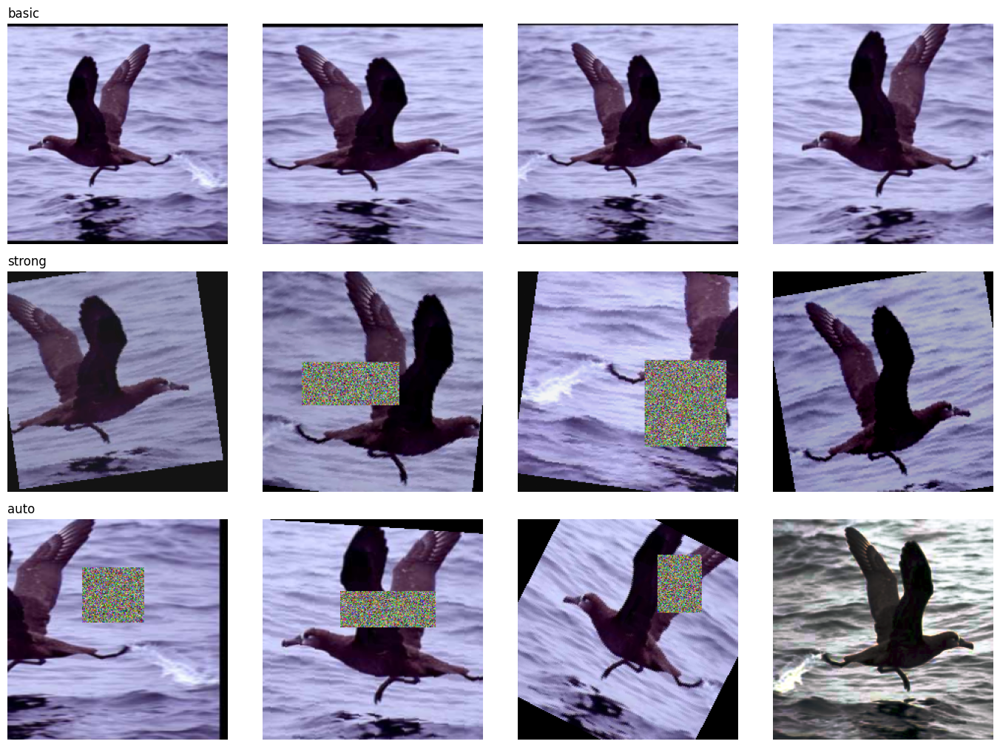

In [11]:
norm = T.Normalize(MEAN, STD)

tfm_none = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), norm])

tfm_basic = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(),
    T.ToTensor(), norm,
])

tfm_strong = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.35, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.0),
    T.ToTensor(), norm,
    T.RandomErasing(p=0.25, scale=(0.02, 0.15), value="random"),
])

tfm_auto = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.35, 1.0)),
    T.RandomHorizontalFlip(),
    T.TrivialAugmentWide(),
    T.ToTensor(), norm,
    T.RandomErasing(p=0.25, scale=(0.02, 0.15), value="random"),
])

eval_tfm = tfm_none     # val/test: deterministic, identical for CNN and ViT

def make_loader(frame, tfm, shuffle, col="filepath", batch_size=BATCH_SIZE, workers=NUM_WORKERS):
    g = torch.Generator(); g.manual_seed(SEED)
    def _wi(_):
        s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)
    return DataLoader(_DS(frame, tfm, col), batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=torch.cuda.is_available(), drop_last=shuffle,
                      worker_init_fn=_wi, generator=g)

# Visual check: the same image through each training pipeline, 4 draws each
def denorm(x):
    return (x * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)).clamp(0, 1)

im = Image.open(train_df.filepath[10]).convert("RGB")
pipes = [("basic", tfm_basic), ("strong", tfm_strong), ("auto", tfm_auto)]
fig, axes = plt.subplots(len(pipes), 4, figsize=(14, 3.4 * len(pipes)))
for r, (name, tf) in enumerate(pipes):
    for c in range(4):
        axes[r, c].imshow(denorm(tf(im)).permute(1, 2, 0)); axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left")
plt.tight_layout(); plt.show()

## E. Augmentation Pipelines

**What this step does**
- Defines four preprocessing pipelines of increasing strength, so the effect of augmentation can be measured (experiment E4).
- Defines `make_loader`, which builds a DataLoader for any pipeline with a fixed seed.
- Shows the same training image (a bird over water) passed through each pipeline four times, to check the results look sensible.

**The four pipelines**

| Pipeline | Steps | Role |
|---|---|---|
| `tfm_none` | Resize to 224 × 224, normalize | No augmentation. Also used as the **val/test transform** |
| `tfm_basic` | Random crop (0.5–1.0), horizontal flip, normalize | Baseline recipe |
| `tfm_strong` | Random crop (0.35–1.0), flip, small affine (±10°, 5% shift, 0.9–1.1 zoom), mild brightness/contrast/saturation jitter, normalize, random erasing (p = 0.25) | Main augmentation recipe |
| `tfm_auto` | Random crop (0.35–1.0), flip, TrivialAugmentWide, normalize, random erasing (p = 0.25) | Optional automatic policy |

**Design choices**
- **Hue is kept at 0**, because plumage color identifies many species.
- **Random erasing runs after normalization**, so the random noise is on the same scale as the image data.
- **Val and test are never augmented**, so their results are deterministic and identical for the CNN and the ViT.
- **`make_loader`** fixes the shuffle seed and each worker's random seed, and drops the last incomplete batch during training, so runs are reproducible.

**What the figure shows**
- **Basic (top row):** the bird stays fully visible, with different zoom levels and left/right flips. Variation is mild.
- **Strong (middle row):** much more variety.
  - Tilted images with black corners from the affine step.
  - Colored noise patches from random erasing. Two of the four draws got one, which is chance, since the probability is 0.25.
  - Tighter crops, with the bird partly cut off in some. This is the cost of the 0.35 lower bound.
- **Auto (bottom row):** strong geometric changes (a rotation, black edges) plus erasing, and one draw where the colors look washed out and the contrast changed. This confirms that automatic policies can alter the colors that identify a species, which is why `auto` is an optional experiment and not the default.

**What this means for the project**
- Augmentation is the main tool for a small-data ViT. It turns about 27 images per class into many different views.
- Stronger augmentation slows training, so `tfm_strong` may need more epochs to pay off. Compare the **learning curves**, not just the final accuracy.
- Use the **same recipe for the CNN and the ViT** in the matched comparison (E1), and change it only in E4.
- Planned E4 comparison: `none` vs `basic` vs `strong` (and `auto` if time allows).

## F. Mixup and CutMix
Both blend two images in a batch and blend their labels to match.
- **Mixup:** pixel-wise blend of two images.
- **CutMix:** paste a rectangle from one image into another. The label weights follow the pasted area.

They are strong regularizers and are part of the DeiT recipe your proposal cites. They need **soft targets**, so the loss changes too.

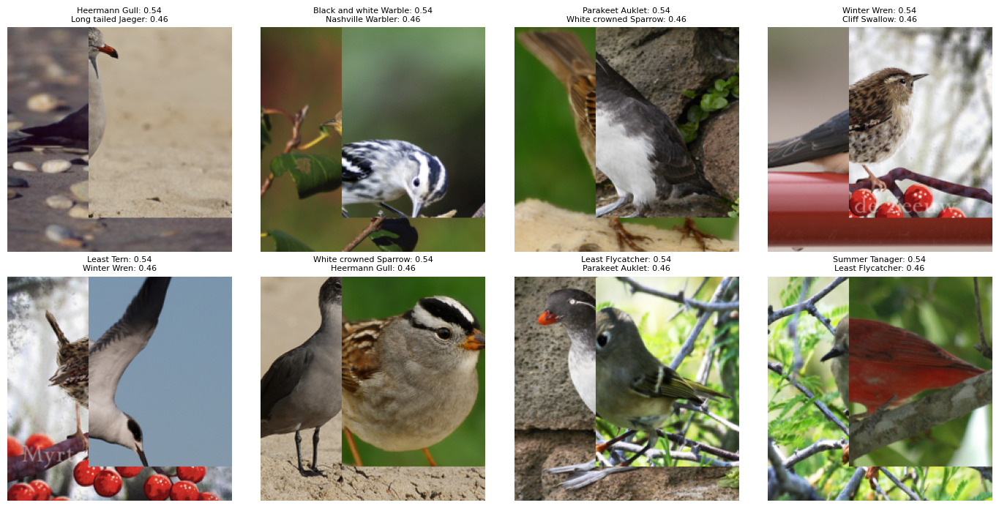

soft-label rows sum to 1: True


In [12]:
def mixup_cutmix(x, y, num_classes=200, mixup_alpha=0.2, cutmix_alpha=1.0, p_cutmix=0.5):
    """Apply Mixup or CutMix to a batch (x: B,C,H,W float; y: B long). Returns mixed x and soft labels (B, num_classes)."""
    onehot = F.one_hot(y, num_classes).float()
    perm = torch.randperm(x.size(0))
    if random.random() < p_cutmix:
        lam = float(np.random.beta(cutmix_alpha, cutmix_alpha))
        H, W = x.shape[-2:]
        rh, rw = int(H * np.sqrt(1 - lam)), int(W * np.sqrt(1 - lam))
        cy, cx = np.random.randint(H), np.random.randint(W)
        top, bot = max(cy - rh // 2, 0), min(cy + rh // 2, H)
        lef, rig = max(cx - rw // 2, 0), min(cx + rw // 2, W)
        x = x.clone(); x[:, :, top:bot, lef:rig] = x[perm][:, :, top:bot, lef:rig]
        lam = 1 - ((bot - top) * (rig - lef)) / (H * W)          # exact kept-area fraction
    else:
        lam = float(np.random.beta(mixup_alpha, mixup_alpha))
        x = lam * x + (1 - lam) * x[perm]
    soft = lam * onehot + (1 - lam) * onehot[perm]
    return x, soft

def soft_target_ce(logits, soft):
    return -(soft * F.log_softmax(logits, dim=1)).sum(dim=1).mean()

# Visual check
xb, yb = next(iter(make_loader(train_df, tfm_basic, shuffle=True, batch_size=16)))
names = df.drop_duplicates("label").set_index("label")["class_name"].sort_index()
torch.manual_seed(1); random.seed(1); np.random.seed(1)
xm, sm = mixup_cutmix(xb, yb, p_cutmix=0.5)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, s in zip(axes.ravel(), xm, sm):
    top2 = torch.topk(s, 2)
    ax.imshow(denorm(img).permute(1, 2, 0)); ax.axis("off")
    ax.set_title("\n".join(f"{names[i.item()][:22]}: {v:.2f}" for v, i in zip(top2.values, top2.indices)), fontsize=8)
plt.tight_layout(); plt.show()
print("soft-label rows sum to 1:", torch.allclose(sm.sum(1), torch.ones(sm.size(0))))

## F. Mixup and CutMix

**What this step does**
- Defines `mixup_cutmix`, which blends the images in a batch and blends their labels to match:
  - **Mixup:** pixel-wise blend of two images.
  - **CutMix:** a rectangle from one image is pasted into another.
- Defines `soft_target_ce`, the loss for these blended labels. A normal loss needs one correct class, but a mixed image belongs partly to two classes.
- Shows 8 mixed images from a batch of 16, with the label weights above each one.
- Checks that every soft label sums to 1.

**How it works**
- Each image is paired with another image from the same batch (a random shuffle).
- A mixing weight `lam` is drawn from a Beta distribution. For CutMix, the pasted rectangle's size is set by `lam`, and the label weights are recomputed from the **exact pasted area**.
- With `p_cutmix = 0.5`, each batch uses CutMix half the time and Mixup the other half.
- The label becomes `lam × (class A) + (1 − lam) × (class B)`.

**What the figure shows**
- This draw used **CutMix** for the whole batch. Each image has a rectangular patch from a different bird, for example a Heermann Gull mixed with a Long-tailed Jaeger, and a Least Tern with a Winter Wren.
- The title above each image lists its two classes and weights. Every image shows **0.54 / 0.46**. That is expected, because one `lam` is drawn per batch, so every image in the batch has the same split.
- The weights follow the pasted area: 0.54 of the image is the original bird and 0.46 is the pasted part.
- The check `soft-label rows sum to 1: True` confirms the soft labels are valid probability distributions.

**What this means for the project**
- Mixup and CutMix are strong regularizers. They stop the model from memorizing individual training images, which is useful with about 27 images per class.
- They make each training signal weaker, so they usually need **longer training** to help. With a short compute budget they can lower accuracy.
- **Fine-grained caution:** the label weight follows the pasted area, not the amount of bird in it. A patch that lands on background or covers only part of the bird still gets its full label weight, which adds some label noise. This is a bigger concern for fine-grained tasks, where the discriminating details are small.
- Label smoothing (already in the proposal) and Mixup/CutMix have overlapping effects, so test them **separately** before combining them.

**Decision**
- Not part of the baseline. Run as an extra ablation inside E4.
- Training with these needs the soft-target loss (`soft_target_ce`) instead of the standard cross-entropy.

## G. Data quality and leakage audit
Two questions: are there images that could cause problems, and do any near-identical photos appear in both train and test? Near-duplicates across splits inflate test accuracy without the model learning anything general.

The duplicate check uses a 64-bit average hash (shrink to 8x8 grayscale, mark pixels above the mean). Photos of the same image at different sizes give hashes that differ by only a few bits.

grayscale images                    8
smaller than 200 px on a side       91
aspect ratio > 2.5 or < 0.5         4
bird covers < 8% of the image       114

cross-split pairs with Hamming distance <= 3: 714
  of which same species (possible leakage): 21

same-species pairs, most similar first:
 pair                     species  hamming  corr           a          b
    0             Bronzed Cowbird        0 1.000  train:1460  test:1413
   16        Prothonotary Warbler        0 1.000 train:10379 test:10371
   20                  Marsh Wren        3 0.916   val:11594 test:11592
   15       Golden winged Warbler        3 0.890  train:9749  test:9758
    3               Brown Creeper        3 0.846  train:1571  test:1550
    5                Horned Grebe        3 0.826  train:2948  test:2926
   12              Vesper Sparrow        3 0.818  train:7664  test:7671
   14                Caspian Tern        3 0.816  train:8384  test:8388
    8               White Pelican        2 0.747  train:59

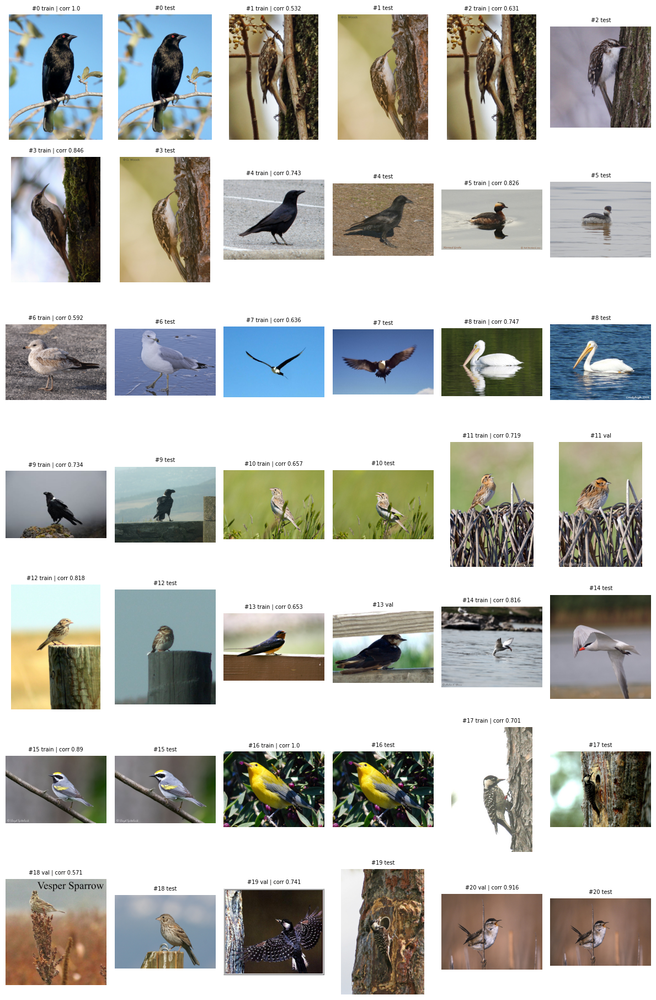

In [15]:
flags = {
    "grayscale images": (df["mode"] != "RGB").sum(),
    "smaller than 200 px on a side": (np.minimum(df.width, df.height) < 200).sum(),
    "aspect ratio > 2.5 or < 0.5": ((df.aspect > 2.5) | (df.aspect < 0.5)).sum(),
    "bird covers < 8% of the image": (df.bbox_frac < 0.08).sum(),
}
for k, v in flags.items(): print(f"{k:35s} {v}")

def ahash(fp, size=8):
    with Image.open(fp) as im:
        g = np.asarray(im.convert("L").resize((size, size), Image.BILINEAR), dtype=np.float32)
    bits = (g > g.mean()).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

df["ahash"] = df["filepath"].map(ahash)
Hs = np.array(df["ahash"].tolist(), dtype=np.uint64)
split_arr = df["split"].values
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
MAXD, n = 3, len(Hs)

pairs = []
for s in range(0, n, 512):
    xor = Hs[s:s + 512, None] ^ Hs[None, :]                          # (chunk, n) uint64
    d = POP[xor.view(np.uint8)].reshape(xor.shape[0], n, 8).sum(-1)   # Hamming distances
    ii, jj = np.where(d <= MAXD)
    for i, j in zip(ii + s, jj):
        if i < j and split_arr[i] != split_arr[j]:
            pairs.append((i, j, int(d[i - s, j])))

print(f"\ncross-split pairs with Hamming distance <= {MAXD}: {len(pairs)}")
same_cls = [(i, j, dist) for i, j, dist in pairs if df.label.iloc[i] == df.label.iloc[j]]
print("  of which same species (possible leakage):", len(same_cls))

if same_cls:
    # Second check on the same-species pairs: correlation of 32x32 grayscale thumbnails.
    # Near 1.0 = same photo; low values = different photos that only share a layout.
    def thumb(fp, size=32):
        with Image.open(fp) as im:
            return np.asarray(im.convert("L").resize((size, size), Image.BILINEAR), dtype=np.float32).flatten()

    rows = []
    for p, (i, j, dist) in enumerate(same_cls):
        c = float(np.corrcoef(thumb(df.filepath.iloc[i]), thumb(df.filepath.iloc[j]))[0, 1])
        rows.append({"pair": p, "species": df.class_name.iloc[i], "hamming": dist, "corr": round(c, 3),
                     "a": f"{df.split.iloc[i]}:{df.image_id.iloc[i]}",
                     "b": f"{df.split.iloc[j]}:{df.image_id.iloc[j]}"})
    pair_table = pd.DataFrame(rows)
    print("\nsame-species pairs, most similar first:")
    print(pair_table.sort_values("corr", ascending=False).to_string(index=False))

    # Show ALL same-species pairs, 3 pairs per row
    per_row = 3
    n_rows = int(np.ceil(len(same_cls) / per_row))
    fig, axes = plt.subplots(n_rows, per_row * 2, figsize=(4 * per_row, 2.6 * n_rows))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel(): ax.axis("off")
    for p, (i, j, dist) in enumerate(same_cls):
        r, c0 = divmod(p, per_row)
        for off, k in enumerate((i, j)):
            ax = axes[r, c0 * 2 + off]
            ax.imshow(Image.open(df.filepath.iloc[k]).convert("RGB"))
            title = f"#{p} {df.split.iloc[k]}"
            if off == 0: title += f" | corr {rows[p]['corr']}"
            ax.set_title(title, fontsize=7)
    plt.tight_layout(); plt.show()

## G. Data Quality and Leakage Audit

**What this step does**
- **Quality flags:** counts images that could cause problems in preprocessing or training.
- **Leakage check:** looks for near-identical photos in different splits. A duplicate across splits inflates test accuracy without the model learning anything general.
- How the duplicate check works: each image is shrunk to 8 × 8 grayscale and turned into a 64-bit fingerprint (average hash). Pairs in different splits whose fingerprints differ by 3 bits or fewer are flagged. For same-species pairs, a second score (`corr`, the correlation of 32 × 32 thumbnails) is added, where 1.0 means the same photo. Every same-species pair was then inspected visually.

**Quality flags (11,788 images in total)**

| Check | Images | Share |
|---|---|---|
| Grayscale | 8 | 0.07% |
| Smaller than 200 px on a side | 91 | 0.8% |
| Aspect ratio > 2.5 or < 0.5 | 4 | 0.03% |
| Bird covers < 8% of the image | 114 | 1.0% |

- **Grayscale (8):** converted to RGB in the Dataset class so every input has 3 channels.
- **Small images (91):** upscaled to 224 × 224, so they carry less fine detail.
- **Extreme aspect ratios (4):** negligible.
- **Tiny birds (114):** under 8% of the image is a bird smaller than about 63 × 63 px after resizing (about 4 × 4 patches at 16 × 16). These are the hardest cases for the ViT and support the 8 × 8 patch experiment (E2).

**Leakage check**
- **714** cross-split pairs were flagged by the hash. Most are false positives, because an 8 × 8 hash is very coarse and unrelated photos with a similar layout get similar fingerprints.
- Only pairs of the **same species** can be real leakage, and there are **21** of them. All 21 were reviewed.

| Finding | Pairs | Species (splits) | corr |
|---|---|---|---|
| Identical photo | #0, #16 | Bronzed Cowbird (train/test), Prothonotary Warbler (train/test) | 1.000 |
| Same photo, likely resized or cropped | #15, #20 | Golden-winged Warbler (train/test), Marsh Wren (val/test) | 0.89, 0.92 |
| Similar scene, different photo | other 17 | e.g. Brown Creeper, Horned Grebe, Vesper Sparrow, White Pelican | 0.53 to 0.85 |

- The 17 remaining pairs show the same species in a similar setting (same kind of perch, water or background) but different birds, poses or framing. Two of them (Nelson's Sharp-tailed Sparrow, train/val, and Baird's Sparrow, train/test) look like shots from the same photo session, but they are separate photographs and were kept.
- **4 images** are true or likely duplicates. This is about 0.07% of the training data and 0.05% of the test set, so the effect on results would be tiny, but the check is still worth reporting.

**Decision**
- **Remove the duplicate copy from the training or validation side** (3 train images and 1 val image). The **test set is left untouched**.
- Final split sizes: **5,391 train, 599 validation, 5,794 test**.
- Keep all quality-flagged images. Together they are about 2% of the data, and removing images from an already small dataset costs more than it gains. They are also valid, difficult examples.
- The updated split files are saved and shared with the whole group so everyone trains on the identical data.

**Limitation**
- The hash check finds identical or resized copies but can miss duplicates that were heavily cropped or edited, so it does not guarantee zero overlap.

**Implication for the report**
- Pick `NUM_WORKERS` from this table, not by habit. If the cached throughput is much higher, train from the cache.
- A loader that cannot keep the GPU busy is the cheapest thing to fix before your long runs.

## H. Save the configuration
So every group member, and your final report, uses identical settings.

In [17]:
config = {
    "seed": SEED, "img_size": IMG_SIZE, "batch_size": BATCH_SIZE,
    "mean": MEAN, "std": STD,
    "splits": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "eval_transform": "Resize((224,224)) + Normalize",
    "train_transforms": {
        "none": "Resize + Normalize",
        "basic": "RandomResizedCrop(0.5-1.0) + HFlip",
        "strong": "RandomResizedCrop(0.35-1.0) + HFlip + RandomAffine(10deg, 5% shift, 0.9-1.1 scale) + ColorJitter(b/c/s 0.3, hue 0) + RandomErasing(p=0.25)",
        "auto": "RandomResizedCrop(0.35-1.0) + HFlip + TrivialAugmentWide + RandomErasing(p=0.25)",
    },
    "mixup_cutmix": {"mixup_alpha": 0.2, "cutmix_alpha": 1.0, "p_cutmix": 0.5},
}
(ROOT / "preprocess_config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "seed": 42,
  "img_size": 224,
  "batch_size": 64,
  "mean": [
    0.4859701097011566,
    0.49921685457229614,
    0.43137678503990173
  ],
  "std": [
    0.22647330164909363,
    0.2219720035791397,
    0.2609000504016876
  ],
  "splits": {
    "train": 5394,
    "val": 600,
    "test": 5794
  },
  "eval_transform": "Resize((224,224)) + Normalize",
  "train_transforms": {
    "none": "Resize + Normalize",
    "basic": "RandomResizedCrop(0.5-1.0) + HFlip",
    "strong": "RandomResizedCrop(0.35-1.0) + HFlip + RandomAffine(10deg, 5% shift, 0.9-1.1 scale) + ColorJitter(b/c/s 0.3, hue 0) + RandomErasing(p=0.25)",
    "auto": "RandomResizedCrop(0.35-1.0) + HFlip + TrivialAugmentWide + RandomErasing(p=0.25)"
  },
  "mixup_cutmix": {
    "mixup_alpha": 0.2,
    "cutmix_alpha": 1.0,
    "p_cutmix": 0.5
  }
}


## H. Saving the Configuration

**What this step does**
- Saves every preprocessing setting to one file, `data/preprocess_config.json`, and prints it.
- Purpose: everyone in the group, and the final report, uses identical settings, so results are comparable and reproducible.

**What is stored**

| Setting | Value |
|---|---|
| Random seed | 42 |
| Image size | 224 × 224 |
| Batch size | 64 |
| Normalization mean (R, G, B) | 0.4860, 0.4992, 0.4314 |
| Normalization std (R, G, B) | 0.2265, 0.2220, 0.2609 |
| Split sizes (train / val / test) | 5,394 / 600 / 5,794 |
| Val/test transform | Resize to 224 × 224 + Normalize (no augmentation) |
| Mixup / CutMix | mixup α = 0.2, cutmix α = 1.0, CutMix probability 0.5 |

**Training pipelines**

| Pipeline | Steps |
|---|---|
| `none` | Resize + Normalize |
| `basic` | RandomResizedCrop (0.5–1.0) + horizontal flip |
| `strong` | RandomResizedCrop (0.35–1.0) + flip + RandomAffine (10°, 5% shift, 0.9–1.1 zoom) + ColorJitter (brightness/contrast/saturation 0.3, hue 0) + RandomErasing (p = 0.25) |
| `auto` | RandomResizedCrop (0.35–1.0) + flip + TrivialAugmentWide + RandomErasing (p = 0.25) |

**Notes**
- The normalization values were computed on the **training split only**.
- Validation and test are never augmented, and use the same transform for the CNN and the ViT.
- Mixup/CutMix are not part of any baseline pipeline. They are used only as an extra ablation in E4.
- The CNN baseline and the ViT must both load this file, so the matched comparison (E1) stays fair.

**Summary**
- All preprocessing decisions from sections A to G are recorded in one place. Anyone can rerun an experiment with identical data handling.